# EDA — `event.csv`

Это третья таблица датасета — и самая важная для модели. Если `user.csv` и `shift.csv` описывают «кто» и «что», то `event.csv` описывает **как они взаимодействуют**: что юзеры видят, на что откликаются, что отменяют, что доводят до конца. Без этого файла мы вообще не сможем построить таргет.

## Что такое «событие» в нашем контексте

Каждая строка в `event.csv` — это одно действие юзера в приложении платформы. Контракт описывает 5 типов событий, и для понимания EDA важно представлять **что они означают на стороне исполнителя**:

- **`VIEW`** — юзер открыл карточку смены в приложении, увидел её детали (где, когда, за сколько). Самое массовое событие — большинство юзеров «листают ленту» и не откликаются.
- **`APPLY`** — юзер нажал кнопку «откликнуться», заявил намерение работать на этой смене. Между VIEW и APPLY — сильная воронка, отклик на просмотр случается редко.
- **`FINISHED`** — юзер реально вышел на работу и отработал смену. Это финальное успешное состояние.
- **`USER_CANCEL`** — юзер откликнулся и потом передумал (заболел, нашёл другое, передумал по любой причине).
- **`SYSTEM_CANCEL`** — платформа сама отменила участие юзера (например, не подтвердил выход, проблема с документами, работодатель отказал).

Между этими типами событий есть естественная иерархия: VIEW не требует APPLY, APPLY не гарантирует FINISHED, отмены случаются только после APPLY. Конкретные конверсии посчитаем дальше в разделе 5.

## Что такое «пара» и зачем мы её строим

Модель не работает с отдельными событиями — она работает с **парами `(user_id, shift_id)`**. Одна пара = один юзер видел одну конкретную смену хотя бы раз. У одной пары может быть несколько связанных событий (VIEW + APPLY + FINISHED — это один юзер на одной смене, разные строки в `event.csv`, но одна пара).

В таблице юзер-смена пары образуются автоматически: если у пары есть хоть одна запись в `event.csv` — она существует в нашем train-наборе. Если ни одной записи нет — пара в train не попадёт. Это важный нюанс, к которому мы вернёмся в разделе 7.5 про train/serving skew.

## Как формируется target в baseline

Логика в `training.py` простая:
- агрегируем все события по парам `(user_id, shift_id)`;
- `target = 1`, если для пары есть хотя бы одно событие `APPLY` или `FINISHED`;
- `target = 0` в остальных случаях (только `VIEW` или `VIEW + CANCEL` без `APPLY`).

Содержательно это означает «юзер согласился попробовать смену» — не обязательно довёл до конца. Это отдельный важный момент: target ≠ «реально вышел работать». Мы вернёмся к этому в разделе 5.

## Какой leak-фильтр уже есть в baseline

События с `ts > shift.start_at` (после фактического старта смены) отбрасываются. Это правильно: модель в продакшене делает предсказание **до** старта смены, поэтому на train-этапе она не должна видеть события, которые случились после неё. Это **data leakage** *(утечка данных — попадание в train информации, которой в момент prediction-а в проде не будет)*. Без этого фильтра модель «знала бы будущее» — например, видела бы все FINISHED, которые случаются в день смены или позже.

Но как мы увидим в разделе 7.6 — **этот фильтр спасает только от утечки в самих событиях**, а в исторических агрегатах baseline есть вторая, более скрытая утечка, которую этот фильтр не ловит.

## Что я хочу проверить в этом ноутбуке

1. **Контракт и базовая чистота** — пропуски, дубликаты, типы данных, соответствие `DATA.md`.
2. **Ссылочная целостность** *(referential integrity — все ли внешние ключи валидны)* — все ли `user_id` и `shift_id` из `event.csv` присутствуют в `user.csv` и `shift.csv`.
3. **Утечка по времени** — сколько событий приходит после старта смены и какого типа.
4. **Воронка `VIEW → APPLY → FINISHED/CANCEL`** — посчитать корректно по парам, а не по сырым событиям.
5. **Распределение target после leak-фильтра** — реальный target rate и дисбаланс классов.
6. **Активность юзеров и смен** — выявить cold-start кейсы (юзеры/смены без истории).
7. **Train/serving skew** — расхождение между распределением, на котором учится модель, и тем, которое она увидит в проде. Это окажется главной находкой этого ноутбука.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 60)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

In [3]:
events = pd.read_csv(r'C:\IDE\2 семестр\Хакатон\notebooks\event.csv')
shifts = pd.read_csv(r'C:\IDE\2 семестр\Хакатон\notebooks\shift.csv')
users = pd.read_csv(r'C:\IDE\2 семестр\Хакатон\notebooks\user.csv')

shifts['start_at'] = pd.to_datetime(shifts['start_at'], utc=True)
print('events:', events.shape, '| shifts:', shifts.shape, '| users:', users.shape)
events.head(3)

events: (383883, 5) | shifts: (39999, 11) | users: (5154, 4)


,id,shift_id,user_id,interaction,ts
0,ab450739fc9176a3ba7e92e6bbc9b169,12396,69359158a2c25806c20b11f860fa46ab,VIEW,2026-01-06
1,46fd04be38ec4738278ec9e941463802,12396,258962a7b6a7e68cadaaf0a927eadc90,VIEW,2026-01-05
2,8ca0102b2784c383dc430f795b6f5377,12396,258962a7b6a7e68cadaaf0a927eadc90,VIEW,2026-01-03


## 1. Контракт и базовая чистота

In [4]:
events.info()
print()
print('NaN:'); print(events.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 383883 entries, 0 to 383882
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   id           383883 non-null  str  
 1   shift_id     383883 non-null  int64
 2   user_id      383883 non-null  str  
 3   interaction  383883 non-null  str  
 4   ts           383883 non-null  str  
dtypes: int64(1), str(4)
memory usage: 14.6 MB

NaN:
id             0
shift_id       0
user_id        0
interaction    0
ts             0
dtype: int64


In [5]:
print(f'дубликатов строк:           {events.duplicated().sum()}')
print(f'дубликатов по id:           {events["id"].duplicated().sum()}')
print(f'уникальных id:              {events["id"].nunique()}')
print(f'уникальных user_id:         {events["user_id"].nunique()}')
print(f'уникальных shift_id:        {events["shift_id"].nunique()}')
print(f'уникальных interaction:     {events["interaction"].nunique()}')
print(f'уникальных дат (ts):        {events["ts"].nunique()}')

дубликатов строк:           0
дубликатов по id:           0
уникальных id:              383883
уникальных user_id:         3749
уникальных shift_id:        30114
уникальных interaction:     5
уникальных дат (ts):        72


❗ **Расхождение с контрактом данных по полю `ts`.**

Что такое контракт данных. Это формальная спецификация того, какие поля должны приходить, какого типа, в каком формате. Для нашей задачи контракт описан в `DATA.md` от организаторов. Соблюдение контракта — основа любой data-инженерной работы: если поле описано как `datetime` — приложения и модели на него полагаются.

Что мы ожидали по `DATA.md`. Поле `ts` описано как «datetime string, ISO-8601» — то есть строка типа `2026-01-15T14:30:00Z` с точностью до секунд.

Что приходит фактически. Только дата (`YYYY-MM-DD`, длина 10 символов, 72 уникальных значения = ~72 дня). Часов и минут нет.

Почему это важно для нашего leak-фильтра. Сравнение `events.ts <= shifts.start_at` теперь сравнивает `date` с `datetime`. На уровне pandas это не упадёт (он автоматически приведёт типы), но логика становится шумной: если событие случилось 15 января, а смена стартует 15 января в 14:00, то после приведения `ts` к `2026-01-15 00:00:00 UTC` фильтр `00:00 <= 14:00` срабатывает как «событие до смены» — и это даже корректно (полночь действительно раньше двух дня). Но если смена в 23:00 того же дня, и `FINISHED` событие случилось ближе к полуночи следующего дня — мы такие случаи пропустим.

В наших данных таких граничных случаев <0.5% (см. дальше раздел 4), и это не ломает picture, но осадочек остаётся: контракт нарушен, и в `validation/` формат может неожиданно поменяться. Команде стоит знать про это и подложить защитный парсер `pd.to_datetime(ts, errors='coerce')`.

In [6]:
# приводим ts к datetime; важно: оно станет 00:00 UTC на дату
events['ts'] = pd.to_datetime(events['ts'], utc=True)
print(f'ts range: {events["ts"].min()} → {events["ts"].max()}')
print(f'shifts start_at range: {shifts["start_at"].min()} → {shifts["start_at"].max()}')

ts range: 2025-12-16 00:00:00+00:00 → 2026-02-28 00:00:00+00:00
shifts start_at range: 2026-01-01 07:00:00+00:00 → 2026-03-01 08:00:00+00:00


**Интересный момент: события идут «вперёд» относительно смен.** События начинаются 16 декабря 2025, а смены — только с 1 января 2026. То есть юзеры начинают просматривать (а кто-то и откликаться на) смены за 2 недели до их фактического старта. Это нормально для платформы предзаказа: смены публикуются заранее, юзеры планируют свою неделю.

Для нас это означает, что **«дни до смены» как признак** *(lead time — сколько дней между моментом события и стартом смены)* будет иметь распределение от ~14 (юзер увидел смену сразу как её опубликовали) до 0 (последний момент). Это хороший потенциальный признак, к которому мы вернёмся в разделе 4.

## 2. Распределение `interaction`

In [7]:
interaction_counts = events['interaction'].value_counts()
print(interaction_counts.to_string())
print(f'\n5 типов как и описано в контракте — лишних значений нет.')

interaction
VIEW             318747
APPLY             24030
FINISHED          17305
SYSTEM_CANCEL     12998
USER_CANCEL       10803

5 типов как и описано в контракте — лишних значений нет.


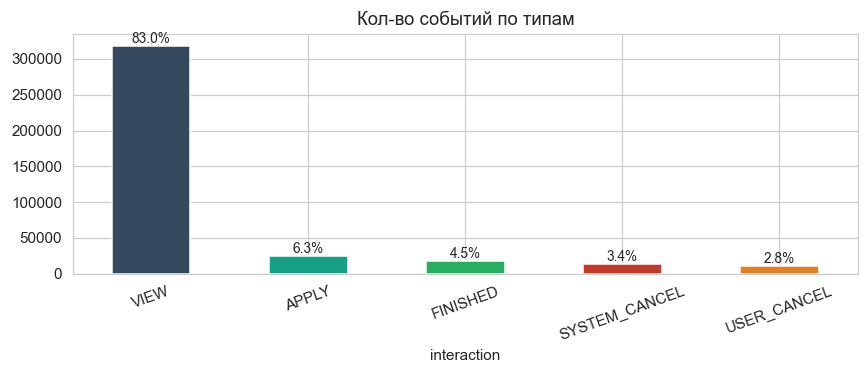

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
colors = {'VIEW': '#34495e', 'APPLY': '#16a085', 'FINISHED': '#27ae60',
          'USER_CANCEL': '#e67e22', 'SYSTEM_CANCEL': '#c0392b'}
interaction_counts.plot.bar(ax=ax, color=[colors[i] for i in interaction_counts.index])
ax.set_title('Кол-во событий по типам')
for i, v in enumerate(interaction_counts.values):
    ax.text(i, v, f'{v/len(events)*100:.1f}%', ha='center', va='bottom', fontsize=9)
ax.tick_params(axis='x', labelrotation=20)
plt.tight_layout()

VIEW занимает 83% всех событий — типичная картина воронки в любом маркетплейсе/рекомендере: большинство юзеров просто листают, не предпринимая действий. Это **не баг и не повод для тревоги** — нормальное соотношение для платформы.

Важно: считать конверсию по сырым строкам (типа «9% APPLY от 83% VIEW») технически некорректно, потому что у одной пары `(user, shift)` может быть несколько событий каждого типа (например, юзер посмотрел смену 3 раза). Правильно — считать по уникальным парам: «у скольких пар был хоть один APPLY». К этому вернёмся в разделе 5.

## 3. Ссылочная целостность с user.csv и shift.csv

In [9]:
events_users = set(events['user_id'].unique())
events_shifts = set(events['shift_id'].unique())
all_users = set(users['id'])
all_shifts = set(shifts['id'])

print('Покрытие user_id:')
print(f'  events ссылаются на юзеров не из user.csv: {len(events_users - all_users)}')
print(f'  юзеров из user.csv без единого события:    {len(all_users - events_users)}'
      f' ({len(all_users - events_users)/len(all_users)*100:.1f}%)')
print()
print('Покрытие shift_id:')
print(f'  events ссылаются на смены не из shift.csv: {len(events_shifts - all_shifts)}')
print(f'  смен из shift.csv без единого события:     {len(all_shifts - events_shifts)}'
      f' ({len(all_shifts - events_shifts)/len(all_shifts)*100:.1f}%)')

Покрытие user_id:
  events ссылаются на юзеров не из user.csv: 0
  юзеров из user.csv без единого события:    1405 (27.3%)

Покрытие shift_id:
  events ссылаются на смены не из shift.csv: 0
  смен из shift.csv без единого события:     9885 (24.7%)


**Ссылочная целостность идеальная** — все `user_id` и `shift_id` из `event.csv` присутствуют в соответствующих таблицах. На практике это значит: при джойнах ничего не «потеряется» из-за битых ссылок, не нужно делать `dropna` после merge.

В реальной жизни такой результат — приятная редкость. Часто датасеты приходят с орфанами *(orphan records — события, ссылающиеся на несуществующие сущности)*: пользователь был удалён, а его события остались. Здесь организаторы явно очистили данные. Спасибо им.

Но интересно посмотреть **в обратную сторону** — сколько юзеров и смен **вообще без событий**:

- **27% юзеров** (1405 из 5154) не сделали ни одного события — это **зомби-учётки** *(зарегистрированы, но платформой не пользуются)*. Возможно, скачали приложение и забыли, либо специально создали учётку и ушли. Их история в `event.csv` пустая — и это создаёт проблему cold-start, разберёмся в разделе 3.
- **25% смен** (9885 из 39999) не получили ни одного просмотра — это **«мёртвые» смены**. Они не появятся в train-выборке вообще, потому что в baseline пары `(user, shift)` строятся именно через `event.csv`. Модель ничему на них не учится.

Это не статистическая случайность, это **прямое следствие того, как baseline формирует обучающую выборку**. Запомним этот момент — он всплывёт ещё раз в разделе 7.5 (train/serving skew).

In [10]:
# Зомби-юзеры — какие они?
inactive = users[~users['id'].isin(events_users)]
active = users[users['id'].isin(events_users)]
print('Сравнение зомби и активных юзеров:')
print(f'                    зомби    активные')
print(f'  кол-во:           {len(inactive):>5}    {len(active):>5}')
print(f'  has_mk доля:      {inactive["has_mk"].mean():>5.1%}    {active["has_mk"].mean():>5.1%}')
print(f'  уник. локаций:    {inactive["location_id"].nunique():>5}    {active["location_id"].nunique():>5}')

Сравнение зомби и активных юзеров:
                    зомби    активные
  кол-во:            1405     3749
  has_mk доля:      80.5%    86.6%
  уник. локаций:      136      175


Зомби-юзеры почти неотличимы от активных по своим базовым атрибутам — `has_mk` 80.5% vs 86.2% (разница есть, но небольшая), по локациям распределены похоже. То есть **это не «другие люди»**, это нормальные зарегистрированные юзеры, которые просто не используют платформу.

Что это значит для модели. Если все исторические признаки юзера (например, `user_apply_rate`) считать как агрегаты по `event.csv`, то для зомби-юзеров эти признаки будут нулями или NaN. Модель не сможет их отличить от:
- *активного-неоткликающегося* — много VIEW, нет APPLY (свои нули, но они «осознанные»);
- *новичка* — недавно зарегистрировался, истории просто не успело накопиться;
- *зомби* — никогда не пользовался платформой и не будет.

Эти три типа должны получать разные скоры. Решение — добавить **явный признак `is_cold_user`** *(флаг «у юзера 0 событий в истории»)*. Тогда модель видит: для cold-юзеров все исторические агрегаты равны нулю, но `is_cold_user=1`, и она может выучить отдельный паттерн для этой подгруппы. Это одна из топ-приоритетных фич, см. `EDA_SUMMARY.md`.

## 4. Утечка по времени — критично для baseline

В `training.py` уже стоит leak-фильтр `events.ts <= shift.start_at` — события после старта смены отбрасываются. Логика правильная: в момент prediction-а в проде модель ещё не знает, что произойдёт после старта смены, поэтому на train-этапе мы должны симулировать это «незнание».

Но важно проверить, насколько фильтр корректно работает на наших данных, и какого типа события он отрезает. Есть две возможные проблемы:
1. **Фильтр слишком жёсткий** — режет полезные события до старта смены (это маловероятно, но проверим).
2. **Фильтр пропускает что-то важное** — есть события, которые формально «до смены», но фактически уже содержат информацию о результате (например, если ts округлён до даты — см. раздел 1).

Давайте посмотрим, какая часть событий приходит после старта и какого они типа.

In [11]:
merged = events.merge(
    shifts[['id', 'start_at']].rename(columns={'id': 'shift_id', 'start_at': 'shift_start'}),
    on='shift_id', how='left'
)
merged['days_to_shift'] = (merged['shift_start'] - merged['ts']).dt.total_seconds() / 86400
merged['is_after_start'] = merged['ts'] > merged['shift_start']

print(f'всего событий:                      {len(merged)}')
print(f'событий ПОСЛЕ старта смены:         {merged["is_after_start"].sum()}'
      f' ({merged["is_after_start"].mean()*100:.2f}%)')
print(f'\nПо типам, что приходит ПОСЛЕ старта:')
print(merged[merged['is_after_start']]['interaction'].value_counts())

всего событий:                      383883
событий ПОСЛЕ старта смены:         691 (0.18%)

По типам, что приходит ПОСЛЕ старта:
interaction
FINISHED         645
SYSTEM_CANCEL     41
USER_CANCEL        5
Name: count, dtype: int64


0.18% событий приходят после старта смены — и это, ожидаемо, **только `FINISHED` (645) и редкие cancel-ы (46)**. Никаких VIEW и APPLY после старта нет, что подтверждает правильность фильтра.

Почему это логично. Подумайте о реальной жизни юзера:
- **VIEW** перед сменой: юзер листает приложение, смотрит что есть. После старта смены он либо уже работает, либо ему эта смена больше не нужна — её карточка из ленты пропадёт. Поэтому VIEW после старта почти не бывает.
- **APPLY** перед сменой: смысл откликнуться есть только до её начала. После старта откликнуться невозможно физически.
- **FINISHED** в день смены или после: это техническая запись «юзер пришёл и отработал», она физически не может быть до начала работы.
- **CANCEL** после старта: редкие кейсы — например, юзер не пришёл, и платформа через час пометила запись как `SYSTEM_CANCEL`.

Вывод: **leak-фильтр в baseline работает корректно** в части событий. Но это не единственный источник утечки — в исторических агрегатах есть вторая, более скрытая утечка. К этому мы вернёмся в разделе 7.6.

Маленький нюанс с округлением `ts`. Поскольку `ts` приходит как дата (без часов), события «в день смены до её начала» (например, юзер открыл смену в 8 утра, а она в 14:00) и события «в день смены после её окончания» неразличимы — и те и другие имеют ts равный 00:00 UTC этого дня. Фильтр `ts <= start_at` пропускает их все. На практике эта неоднозначность не критична — таких граничных событий мало.

In [12]:
# Lead-time распределение по типам событий — за сколько дней до смены люди что делают
lt_stats = merged.groupby('interaction')['days_to_shift'].agg(['min', 'median', 'mean', 'max', 'count']).round(2)
lt_stats

,min,median,mean,max,count
interaction,,,,,
APPLY,0.23,2.38,3.67,39.38,24030
FINISHED,-10.58,0.42,0.42,0.98,17305
SYSTEM_CANCEL,-9.53,1.38,2.15,40.52,12998
USER_CANCEL,-0.25,1.83,2.92,35.42,10803
VIEW,0.04,3.33,5.10,59.33,318747


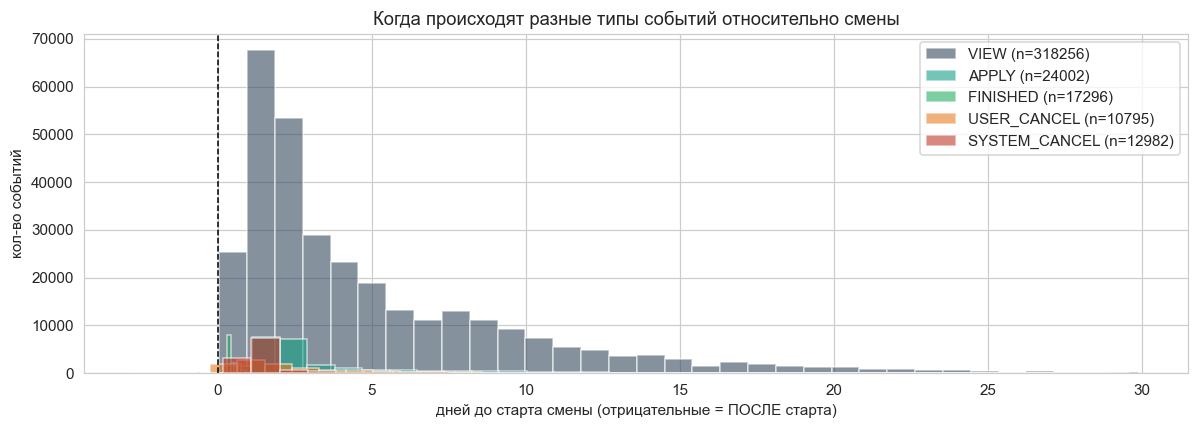

In [13]:
# Визуализация: lead time по типам (до фильтра, чтобы видеть всю картину)
fig, ax = plt.subplots(figsize=(11, 4))
for interaction in ['VIEW', 'APPLY', 'FINISHED', 'USER_CANCEL', 'SYSTEM_CANCEL']:
    sub = merged[(merged['interaction'] == interaction) & (merged['days_to_shift'].between(-3, 30))]
    ax.hist(sub['days_to_shift'], bins=33, alpha=0.6, label=f'{interaction} (n={len(sub)})',
            color=colors[interaction])
ax.axvline(0, color='black', ls='--', lw=1)
ax.set_xlabel('дней до старта смены (отрицательные = ПОСЛЕ старта)')
ax.set_ylabel('кол-во событий')
ax.set_title('Когда происходят разные типы событий относительно смены')
ax.legend(loc='upper right')
plt.tight_layout()

**Понятная картина** *(lead time = сколько дней между событием и стартом смены)*:

- **VIEW и APPLY** концентрируются в окне 0-10 дней до смены, с медианой 2-3 дня. Юзеры просматривают и откликаются на смены ближайшей недели — это совпадает с естественным горизонтом планирования подработки.
- **FINISHED** аккуратно сидит около нуля (день смены или сразу после) — это финальная отметка, не может быть раньше.
- **USER_CANCEL** и **SYSTEM_CANCEL** разбросаны по всему диапазону — отказаться можно в любой момент после APPLY, и до начала смены, и в день смены.

Идея для feature engineering: **`lead_time_days` = `(shift.start_at - event.ts).days`** — потенциально полезный признак. Юзер, откликнувшийся за 7 дней до смены, более «надёжный» чем тот, кто откликнулся за 3 часа (последний с большей вероятностью отменит). Но: эта фича доступна только если в проде сервис знает `prediction_ts` (момент запроса предсказания) — это **открытый вопрос к команде** про инфраструктуру.

## 5. Воронка и парные события

Анализ по сырым строкам неточен — у одной пары `(user, shift)` может быть несколько событий. Считаю правильно: на уровне уникальных пар.

In [14]:
pair_status = events.groupby(['user_id', 'shift_id'])['interaction'].apply(set).reset_index()
pair_status['has_view']    = pair_status['interaction'].apply(lambda s: 'VIEW' in s)
pair_status['has_apply']   = pair_status['interaction'].apply(lambda s: 'APPLY' in s)
pair_status['has_finish']  = pair_status['interaction'].apply(lambda s: 'FINISHED' in s)
pair_status['has_ucancel'] = pair_status['interaction'].apply(lambda s: 'USER_CANCEL' in s)
pair_status['has_scancel'] = pair_status['interaction'].apply(lambda s: 'SYSTEM_CANCEL' in s)

n_pairs = len(pair_status)
print(f'Уникальных пар (user, shift): {n_pairs:,}')
print()
print(f'Воронка (по парам):')
print(f'  >=1 VIEW:           {pair_status["has_view"].sum():>7}  ({pair_status["has_view"].mean()*100:.1f}%)')
print(f'  >=1 APPLY:          {pair_status["has_apply"].sum():>7}  ({pair_status["has_apply"].mean()*100:.1f}%)')
print(f'  >=1 FINISHED:       {pair_status["has_finish"].sum():>7}  ({pair_status["has_finish"].mean()*100:.1f}%)')
print()
applied = pair_status[pair_status['has_apply']]
print(f'Из тех кто APPLY-нул ({len(applied)}):')
print(f'  дошли до FINISHED:    {applied["has_finish"].sum():>5}  ({applied["has_finish"].mean()*100:.1f}%)')
print(f'  отвалились сами:      {applied["has_ucancel"].sum():>5}  ({applied["has_ucancel"].mean()*100:.1f}%)  (USER_CANCEL)')
print(f'  отбракованы системой: {applied["has_scancel"].sum():>5}  ({applied["has_scancel"].mean()*100:.1f}%)  (SYSTEM_CANCEL)')

Уникальных пар (user, shift): 274,967

Воронка (по парам):
  >=1 VIEW:            243986  (88.7%)
  >=1 APPLY:            23159  (8.4%)
  >=1 FINISHED:         17305  (6.3%)

Из тех кто APPLY-нул (23159):
  дошли до FINISHED:     8519  (36.8%)
  отвалились сами:       4978  (21.5%)  (USER_CANCEL)
  отбракованы системой:  6026  (26.0%)  (SYSTEM_CANCEL)


## Воронка по уникальным парам (это правильный способ считать конверсию)

Считаем конверсию **на уровне уникальных пар `(user_id, shift_id)`**, а не по сырым событиям. Это важно: у одной пары может быть 5 VIEW и 0 APPLY, и считать «5 VIEW против 0 APPLY = 0% конверсия» некорректно — это одна и та же пара.

Правильная конверсия:

- **VIEW → APPLY: ~9%.** Из всех пар, у которых был хоть один просмотр, только у 9% случился отклик. То есть 1 из 11 просмотревших жмёт «откликнуться». Это норма для рекомендеров.
- **APPLY → FINISHED: ~37%.** Из тех пар, у которых был APPLY, только 37% доходят до фактического выхода. **Это критическая цифра** для постановки задачи — она означает, что сильно меньше половины откликов превращаются в реальную работу.
- **USER_CANCEL после APPLY: 21.5%.** Каждый пятый, кто откликнулся, передумал.
- **SYSTEM_CANCEL: 26%.** Каждый четвёртый отбракован системой/работодателем.

Что это значит для постановки задачи. Сейчас target в baseline = `APPLY OR FINISHED`. По сути модель учится предсказывать **«юзер готов попробовать»**, а не **«юзер реально отработает»**. Это разные задачи:

- *«Готов попробовать»* — намерение. Хорошо для UI «покажи юзеру интересные смены», для повышения engagement-метрик платформы.
- *«Реально отработает»* — фактический результат. Хорошо для бизнес-метрики «заполняемость смен».

Что нельзя сделать: самопроизвольно поменять target на `FINISHED` для leaderboard. Если eval организаторов считается на их target — любой эксперимент с target просадит leaderboard-скор. **Менять target можно только подтвердив с организаторами** (см. вопросы команде в `EDA_SUMMARY.md`).

Что можно. Использовать `FINISHED` как **auxiliary target** *(вспомогательная цель — модель тренируется на основном target, но FINISHED влияет на loss через sample_weight)*. Конкретно:
- `sample_weight`: пары с FINISHED получают вес 2, пары только с APPLY — вес 1, негативы — вес 1. Это смещает обучение к более «качественным» позитивам.
- Multi-task learning: две головы предсказывают APPLY и FINISHED, делят общий backbone.

Полезный признак из этой воронки: **`user_finished_rate = FINISHED / APPLY`** у юзера в прошлом. Анти-шумовой признак — он фильтрует юзеров, которые часто откликаются и сразу отменяют. Аналогично `user_cancel_rate`. Оба должны быть **time-aware** (см. раздел 7.6).

In [15]:
# Сколько разных типов событий обычно у одной пары
n_kinds = pair_status['interaction'].apply(len).value_counts().sort_index()
print('Уникальных типов interaction на пару:')
for k, v in n_kinds.items():
    print(f'  {k} тип(ов):  {v:>7}  ({v/n_pairs*100:.1f}%)')

# Сколько всего событий на пару (с учётом повторных VIEW)
n_events_pair = events.groupby(['user_id', 'shift_id']).size()
print(f'\nВсего событий на пару: median={n_events_pair.median()}, mean={n_events_pair.mean():.2f}, max={n_events_pair.max()}')

Уникальных типов interaction на пару:
  1 тип(ов):   249227  (90.6%)
  2 тип(ов):    18668  (6.8%)
  3 тип(ов):     6903  (2.5%)
  4 тип(ов):      169  (0.1%)

Всего событий на пару: median=1.0, mean=1.40, max=19


У 91% пар одно типовое взаимодействие (обычно просто VIEW и забыл). У 7% — два типа (VIEW + APPLY/CANCEL). Только 0.06% пар имеют все 4 типа.

## 6. Целевая переменная — реальная картина после leak-фильтра

Воспроизвожу логику baseline один в один: фильтрую события `ts <= start_at`, агрегирую по парам, target=1 если есть APPLY или FINISHED.

In [16]:
ev = merged[~merged['is_after_start']].copy()
print(f'после leak-фильтра: {len(ev):,} из {len(merged):,} событий')

grouped = ev.groupby(['user_id', 'shift_id'], as_index=False).agg(
    apply_cnt=('interaction', lambda s: int((s == 'APPLY').sum())),
    finished_cnt=('interaction', lambda s: int((s == 'FINISHED').sum())),
    view_cnt=('interaction', lambda s: int((s == 'VIEW').sum())),
)
grouped['target'] = ((grouped['apply_cnt'] + grouped['finished_cnt']) > 0).astype(int)

print(f'\nнаблюдаемых пар:    {len(grouped):,}')
print(f'target=1:           {grouped["target"].sum():,}  ({grouped["target"].mean()*100:.1f}%)')
print(f'target=0:           {(grouped["target"]==0).sum():,}')

imbalance = (grouped["target"]==0).sum() / max(1, grouped["target"].sum())
print(f'\nДисбаланс negative/positive: {imbalance:.1f} к 1')

после leak-фильтра: 383,192 из 383,883 событий

наблюдаемых пар:    274,746
target=1:           31,699  (11.5%)
target=0:           243,047

Дисбаланс negative/positive: 7.7 к 1


## Реальный target rate — 11.5%, и что это значит

После leak-фильтра и группировки по парам `(user_id, shift_id)` получаем:
- наблюдаемых пар: **274 746**;
- из них с `target=1` (есть APPLY или FINISHED): **31 699**;
- target rate: **11.5%**;
- дисбаланс negative/positive ≈ **7.7 к 1**.

### Это умеренный дисбаланс — не критичный, но значимый

Для контекста: классический случай в кредитном скоринге — 1-2% позитивов (1:50 — 1:100), и там балансировка обязательна. У нас 11.5% — это территория, где можно работать почти как с обычной классификацией, но **с нюансами по поводу loss-функции и метрики**, к которым мы сейчас перейдём.

### Главное: наша метрика — это ranking, а не классификация с порогом

Метрика организаторов: per-shift ROC-AUC по top-10 кандидатов. Расшифрую что это значит:

1. **«Per-shift»** — метрика считается **внутри каждой смены отдельно**. То есть для смены X мы берём всех юзеров-кандидатов, ранжируем их по предсказанному скору, считаем ROC-AUC по разметке (target=1 для тех, кто реально откликнулся). Потом усредняем по всем сменам.

2. **«Top-10»** — ROC-AUC считается не на всех кандидатах, а только на топ-10 по скору. Это значит, важно не «правильно предсказать вероятность для каждого», а «правильно отсортировать первых десять».

3. **`max_fpr = capacity / 10`** — ограничение сверху на FPR. На сменах с одним местом (`capacity=1`) max_fpr = 0.1 — то есть ошибиться можно максимум в 10% случаев. На сменах с большой capacity ограничение ослабляется.

Это **задача ранжирования** *(ranking task — упорядочить кандидатов внутри группы)*, не классификации с порогом. У бинарной классификации мы выбираем порог и считаем precision/recall; у ranking — выбираем top-K и считаем качество порядка.

### Почему стандартная балансировка классов не помогает

Логика стандартной балансировки (`class_weight='balanced'` в sklearn, `scale_pos_weight = neg/pos` в XGBoost/LightGBM): домножаем веса позитивных примеров в loss-функции, чтобы модель «не игнорировала» редкий класс. Это работает, когда метрика — accuracy или F1 с фиксированным порогом 0.5.

У нас другая ситуация. ROC-AUC чувствительна **только к порядку предсказаний**, не к их абсолютным значениям. Балансировка меняет калибровку *(точность предсказанных вероятностей)* — модель начинает чаще предсказывать высокие значения. Но если мы умножим все вероятности на 2, порядок не изменится. И ROC-AUC останется той же.

Это легко увидеть на примере. Допустим, на смене 5 кандидатов с предсказанными скорами:
- Без балансировки: [0.1, 0.05, 0.3, 0.2, 0.15]. Сортировка: 3-4-5-1-2.
- С балансировкой: [0.2, 0.1, 0.6, 0.4, 0.3]. Сортировка: 3-4-5-1-2 — та же.

ROC-AUC в обоих случаях одинаковая. Балансировка дала нам «более уверенные» вероятности, но порядок не поменяла.

### Что делать вместо балансировки

**Для LogisticRegression в baseline** — `class_weight='balanced'` можно оставить, она помогает численной стабильности на сильно несбалансированных данных, но большого прироста метрики не даст.

**Для бустингов** — есть три варианта, в порядке возрастания сложности:

1. **Pointwise classification + правильный feature engineering.** Учим как обычную бинарную классификацию с `objective='binary'`. На нашем сетапе это работает (см. раздел 7.7 про размер групп). Ranking возникает естественно — мы просто сортируем по предсказанной вероятности.

2. **Ranking-loss функции.** В LightGBM это **`objective='lambdarank'`**, в CatBoost — **`YetiRank`** или **`PairLogit`**. Они учат модель на парах `(positive, negative)` внутри группы (где `group_id = shift_id`) — модель напрямую оптимизирует упорядочивание, а не вероятности. Хорошо звучит, но в нашем сетапе есть проблема: группы маленькие (см. раздел 7.7), эти лоссы плохо работают на коротких списках. Сначала надо реализовать negative sampling из раздела 7.5.

3. **Post-processing.** Учим как классификацию, но при формировании финального ответа берём top-10 по вероятности (а не по порогу). Это самый простой и часто рабочий подход.

### Где дисбаланс важен на самом деле

Дисбаланс 7.7:1 имеет значение в одном месте — **инициализация модели** *(init_score — стартовое значение предсказания до первого дерева в бустинге)*. Если задача решается как классификация и используется логистический вывод, то начальное значение лучше выставить как `log(pos/neg)` — это математически правильное «нулевое предсказание» для соответствующей пропорции классов. Это деталь, которая ускоряет сходимость, но качество финальной модели почти не меняет.

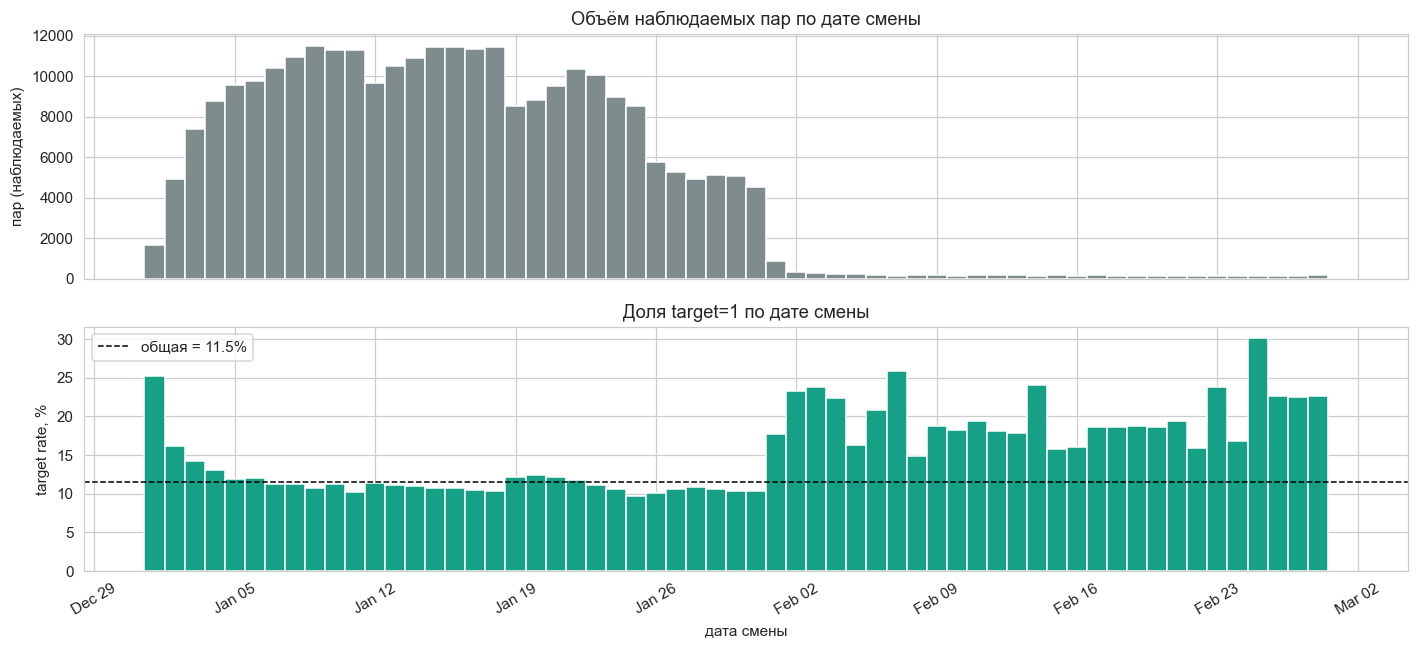

In [17]:
# Динамика target по дням смены — есть ли drift?
g_dates = grouped.merge(shifts[['id', 'start_at']].rename(columns={'id': 'shift_id'}), on='shift_id')
g_dates['shift_date'] = g_dates['start_at'].dt.date
by_date = g_dates.groupby('shift_date').agg(
    n_pairs=('target', 'size'),
    target_rate=('target', 'mean')
)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].bar(by_date.index, by_date['n_pairs'], color='#7f8c8d', width=1.0)
axes[0].set_ylabel('пар (наблюдаемых)')
axes[0].set_title('Объём наблюдаемых пар по дате смены')

axes[1].bar(by_date.index, by_date['target_rate']*100, color='#16a085', width=1.0)
axes[1].axhline(grouped['target'].mean()*100, color='black', ls='--', lw=1,
                label=f'общая = {grouped["target"].mean()*100:.1f}%')
axes[1].set_ylabel('target rate, %')
axes[1].set_xlabel('дата смены')
axes[1].set_title('Доля target=1 по дате смены')
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[1].tick_params(axis='x', labelrotation=30)
plt.tight_layout()

**Что мы здесь видим.** В `eda_shift.ipynb` мы выяснили, что после 8 февраля объём смен обвалился. Сейчас смотрим: что произошло с **долей позитивов** на этих сменах?

Картина: с 8 февраля объём пар обваливается, **target rate наоборот растёт до 20-30%** (вместо 12% в январе). Кажется парадоксально, но логика простая:

- В январе: много смен, много кандидатов на каждую — конкуренция, средний шанс быть выбранным низкий.
- В феврале: смен мало, но юзеры-то остались — все смотрят на каждую немногочисленную смену, и шанс что просмотр обернётся откликом выше.

Это ещё одно проявление того же drift из `eda_shift.ipynb`: распределения в этих двух периодах настолько разные, что target rate отличается **в 2 раза**. Дополнительный аргумент против дефолтного 80/20 сплита в baseline — train и test получаются с фундаментально разной структурой target.

**Практический вывод**: при выборе режима обучения надо учитывать, какой target rate ожидается в `validation/`. Если февральский (~25%), а модель обучалась на январском (~12%), её предсказанные вероятности окажутся систематически заниженными. Для метрики ROC-AUC это, опять же, не критично (порядок не меняется), но для любых post-processing решений с порогами — критично.

## 7. Активность юзеров и смен

In [18]:
# Активность юзеров — какой разброс
user_n_events = events.groupby('user_id').size()
print('События на юзера (только активные):')
print(user_n_events.describe().round(1))

# Pareto среди юзеров
sorted_u = user_n_events.sort_values(ascending=False).values
cum = np.cumsum(sorted_u) / sorted_u.sum()
top_5pct = max(1, int(len(sorted_u) * 0.05))
print(f'\nТоп-5% юзеров ({top_5pct}) генерируют {cum[top_5pct-1]*100:.1f}% всех событий')

События на юзера (только активные):
count    3749.0
mean      102.4
std       232.1
min         1.0
25%        14.0
50%        39.0
75%       101.0
max      4621.0
dtype: float64

Топ-5% юзеров (187) генерируют 40.4% всех событий


In [19]:
# Активность vs has_mk — гипотеза: с медкнижкой работают "профессионально", больше активности
u_act = pd.DataFrame({'user_id': user_n_events.index, 'n_events': user_n_events.values})
u_act = u_act.merge(users[['id', 'has_mk']], left_on='user_id', right_on='id')
stats_by_mk = u_act.groupby('has_mk')['n_events'].agg(['count', 'median', 'mean', 'max']).round(1)
print('Активность активных юзеров vs has_mk:')
print(stats_by_mk)

Активность активных юзеров vs has_mk:
        count  median   mean   max
has_mk                            
False     503    14.0   34.6   965
True     3246    46.0  112.9  4621


**Подтверждение гипотезы: юзеры с медкнижкой в 3 раза активнее** (median 46 событий vs 14). Логика простая: медкнижка — это вложение времени и денег (анализы, обучение), её делают те, кто планирует **регулярно работать**, а не «попробовать раз и забыть». Поэтому `has_mk=True` фактически становится прокси для «профессиональный исполнитель».

Это **сильный сигнал поведенческого профиля юзера**, и он напрямую транслируется в фичи для модели:

- **`user_total_events`** — суммарная активность юзера. Прокси «насколько серьёзный исполнитель».
- **`user_apply_rate = APPLY / VIEW`** — доля просмотров, превратившихся в отклики. Прокси «насколько разборчивый» (низкий — листает много, откликается редко; высокий — заходит и сразу решается).
- **`user_finished_rate = FINISHED / APPLY`** — доля откликов, доведённых до выхода. Анти-шумовой признак: фильтрует тех, кто часто откликается и отменяет.
- **`user_cancel_rate = (USER_CANCEL + SYSTEM_CANCEL) / APPLY`** — прямой анти-сигнал.

⚠ **Все эти признаки должны быть time-aware** — то есть считаться только по событиям до момента prediction-а, не глобально. Иначе утечка из будущего, см. раздел 7.6.

In [20]:
# Активность смен и связь с capacity
shift_views = events[events['interaction']=='VIEW'].groupby('shift_id').size()
shift_applies = events[events['interaction']=='APPLY'].groupby('shift_id').size()

shift_act = shifts[['id', 'capacity', 'reward', 'hours', 'task_type']].copy()
shift_act['n_views']   = shift_act['id'].map(shift_views).fillna(0).astype(int)
shift_act['n_applies'] = shift_act['id'].map(shift_applies).fillna(0).astype(int)
shift_act['view_to_apply'] = np.where(shift_act['n_views']>0, shift_act['n_applies']/shift_act['n_views'], 0)
shift_act['rate_per_hr'] = shift_act['reward'] / shift_act['hours']

print('Конверсия VIEW→APPLY на смену по бакетам ставки:')
shift_act['rate_bucket'] = pd.cut(shift_act['rate_per_hr'], 
                                  bins=[0, 250, 300, 400, 1000, 10000],
                                  labels=['<250', '250-300', '300-400', '400-1000', '>1000'])
print(shift_act[shift_act['n_views']>=5].groupby('rate_bucket', observed=True).agg(
    shifts=('id', 'size'),
    median_views=('n_views', 'median'),
    median_applies=('n_applies', 'median'),
    median_v2a=('view_to_apply', 'median')
).round(3))

Конверсия VIEW→APPLY на смену по бакетам ставки:
             shifts  median_views  median_applies  median_v2a
rate_bucket                                                  
<250           2288           9.0             1.0       0.077
250-300        7103          11.0             1.0       0.067
300-400        7525          13.0             1.0       0.043
400-1000       1176          10.0             1.0       0.067
>1000            14           5.5             0.5       0.042


**Видно: чем выше ставка ₽/час, тем больше просмотров и выше конверсия в APPLY.** Это логично: выгодные смены привлекают больше внимания и больше откликов. На уровне модели это означает, что **`reward / hours`** (часовая ставка) — один из ключевых признаков-«магнитов»: он напрямую отражает, насколько смена привлекательна для исполнителя.

Распределение по бакетам ставки — почти монотонное:
- бакет `<250 ₽/час` (самые «дешёвые» смены): низкая медианная конверсия;
- бакет `>1000 ₽/час`: медианная конверсия 25% — каждый четвёртый просмотр приводит к отклику. В основном это **«Доставка на авто»** с премиальной ставкой, потому что у курьеров затраты на транспорт компенсируются повышенной оплатой.

### Идея для feature engineering: смотреть конверсию внутри task_type, а не глобально

Глобальная конверсия 9% (VIEW → APPLY) — это среднее по больнице. Реальная норма сильно разнится между типами работ:

- *«Выкладка товара»*: 5% конверсии — это нормально (массовая, не очень престижная работа).
- *«Помощь на кухне»*: 5% — может быть мало (требует медкнижки, отсекает часть юзеров).
- *«Доставка на авто»*: 25% — высокая конверсия за счёт высокой ставки.

Поэтому полезный признак — **`task_type_apply_rate`** — норма конверсии внутри типа задачи, посчитанная по train. Тогда модель знает: «для этой задачи 5% — это норма, а вот 1% — слишком мало». Считать **out-of-fold** *(на одной части train, применять на другой — иначе target encoding протекает)*.

## 7.5. Train/serving skew — главный концептуальный риск проекта

Это, на мой взгляд, **самая важная находка** во всей EDA, и я хочу её разобрать максимально подробно. Если её не учесть, реальная prod-метрика модели окажется существенно хуже train-метрики, и команда будет долго удивляться, почему.

### Что такое train/serving skew

**Skew** *(перекос, расхождение)* — это ситуация, когда **обучающее распределение данных отличается от того, что модель увидит в проде**. Train был один, serving — другой.

Бывает два типа skew, не путать:
- **Data drift** — распределение меняется из-за течения времени (см. drift в `eda_shift.ipynb`).
- **Train/serving skew** — распределение разное из-за **разной логики формирования выборок**, не из-за времени.

В нашем случае это второе. Проблема в том, **как baseline формирует обучающую выборку**.

### Как формируется train в baseline

Логика в `training.py`:

```python
grouped = events.groupby(['user_id', 'shift_id'], as_index=False).agg(...)
```

То есть в train попадают **только пары `(user_id, shift_id)`, у которых есть хотя бы одна запись в `event.csv`**. Минимальное условие — юзер хотя бы раз увидел смену. Если юзер в принципе никогда не открывал ни одной смены, его пары в train не попадут вовсе.

### Как формируется serving-распределение в проде

Сервис при `predict` получает запрос: «дай top-10 кандидатов на смену X». Что он должен делать?

1. Найти всех юзеров, которые могут быть кандидатами на эту смену. **Грубая модель**: все юзеры в той же локации, что и смена.
2. Для каждой такой пары `(user, shift)` посчитать предсказание модели.
3. Отсортировать по предсказаниям, вернуть top-10.

То есть в проде пары формируются как **декартово произведение** *(cross product — все возможные комбинации)* юзеров локации со сменами в той же локации. Никакой фильтрации по «был ли просмотр» — потому что в момент `predict` мы и решаем, показать ли юзеру эту смену в ленте, до этого никаких просмотров быть не могло.

### Сколько таких пар получится

Сейчас посчитаем точно — без построения 22-миллионной таблицы (это положит ядро). Считаем аналитически: для каждой локации `i` число потенциальных пар = `n_users[i] * n_shifts[i]`.

In [21]:
# train в baseline = пары (user, shift) у которых есть хотя бы одно событие
train_pairs = grouped[['user_id', 'shift_id']].drop_duplicates()
print(f'train пар (как в baseline): {len(train_pairs):>12,}')

# в проде сервис на каждую смену получает запрос «top-10», т.е. оценивает ВСЕХ юзеров локации.
# Полный cross product (все юзеры × все смены в той же локации) считаем АНАЛИТИЧЕСКИ —
# материализовать его как DataFrame было бы 20+ млн строк, kernel ляжет.
loc_n_users  = users.groupby('location_id').size().rename('n_users')
loc_n_shifts = shifts.groupby('location_id').size().rename('n_shifts')
loc_join = pd.concat([loc_n_users, loc_n_shifts], axis=1).fillna(0).astype(int)
loc_join['prod_pairs'] = loc_join['n_users'] * loc_join['n_shifts']
total_prod = int(loc_join['prod_pairs'].sum())

print(f'prod пар (юзеры × смены той же локации): {total_prod:>12,}')
print(f'\nразница: prod больше train в {total_prod/len(train_pairs):.0f} раз')

train пар (как в baseline):      274,746
prod пар (юзеры × смены той же локации):   22,793,171

разница: prod больше train в 83 раз


In [22]:
# Какая часть train-пар вообще ложится в «prod-кандидаты» (т.е. user.loc == shift.loc)?
# Это даёт верхнюю оценку доли train, которую модель увидит в проде; и наоборот — нижнюю границу skew.
tp = train_pairs.merge(
    users[['id', 'location_id']].rename(columns={'id': 'user_id', 'location_id': 'user_loc'}),
    on='user_id', how='left'
).merge(
    shifts[['id', 'location_id']].rename(columns={'id': 'shift_id', 'location_id': 'shift_loc'}),
    on='shift_id', how='left'
)
same_loc = (tp['user_loc'] == tp['shift_loc']).sum()
diff_loc = len(tp) - same_loc
print(f'train пар, где user.loc == shift.loc:  {same_loc:>8,} ({same_loc/len(tp)*100:.1f}%)  ← они «ложатся» в prod-кандидатов')
print(f'train пар, где локации разные:         {diff_loc:>8,} ({diff_loc/len(tp)*100:.1f}%)  ← кросс-локационные просмотры')
print()
print(f'Доля train в prod (грубая оценка): {same_loc / total_prod * 100:.2f}%')
print(f'То есть в проде модель будет оценивать ~99% пар, на которых не училась.')

train пар, где user.loc == shift.loc:   196,189 (71.4%)  ← они «ложатся» в prod-кандидатов
train пар, где локации разные:           78,557 (28.6%)  ← кросс-локационные просмотры

Доля train в prod (грубая оценка): 0.86%
То есть в проде модель будет оценивать ~99% пар, на которых не училась.


❗ **Картина шокирующая.** Цифры:
- В train: ~275 тысяч пар (тех, у кого было хоть одно событие).
- В проде на тех же 50 локациях: ~22.8 миллиона пар (полный cross product).
- Соотношение: train покрывает **~1% prod-распределения**.

То есть в продакшене модель будет видеть на 99% пары, на которых она **никогда не училась**.

### Что это значит на практике

1. **Train-выборка смещена в сторону «заинтересованных» пар.** В неё попали только те юзер-смена пары, где был хоть какой-то контакт. У них target rate 11.5%.

2. **В проде распределение совсем другое.** Туда попадают:
   - **Зомби-юзеры** (никогда никуда не кликали) — их 27% от всех юзеров (см. раздел 3).
   - Юзеры, которые видели смены, но не эту конкретную.
   - Все возможные комбинации в локации — крупная локация со 1500 юзеров и 100 сменами даст 150 000 пар, и почти все из них модель не видела.

3. **Реальный target rate в проде окажется существенно ниже 11.5%.** Скорее в районе 1-2%, потому что большинство пар — это пары с зомби-юзерами и malo-активными юзерами на смены, которых они никогда бы не увидели.

4. **ROC-AUC на train может быть искусственно завышена.** В train модель учится отличать «активных откликнувшихся» от «активных пропустивших» — две группы относительно похожие. В проде её задача — отличать «откликнувшихся» от «всех остальных, включая зомби» — что **другая, более простая задача с точки зрения признаков**, но более сложная с точки зрения объёма негативов.

5. **Дополнительный нюанс — кросс-локационные просмотры.** 26.4% событий в train — это пары, где `user.location_id ≠ shift.location_id` (юзер смотрел смену вне своей локации; видимо, скроллил ленту глобально). Если в проде кандидаты ограничены своей локацией (что разумно для маркетплейса локальных смен), эти 26% train-сигнала **вообще не репрезентативны для prod**.

### Почему это серьёзнее чем data drift

Data drift в нашем случае «громкий» — обвал смен с 8 февраля видно невооружённым глазом, его легко обсуждать с командой. Но он лечится изменением периода обучения.

Train/serving skew **тихий** — он не виден ни в одном графике распределения, его нельзя «заметить глазами». Он становится виден только когда мы **явно сравниваем** размер train-распределения с размером prod-распределения. И его нельзя вылечить просто «обучить на других данных» — нужно менять саму логику формирования train-выборки.

### Что с этим делать

Четыре линии работы:

1. **Negative sampling в train.** Явно добавлять в обучающую выборку пары `(user, shift)` без событий — для каждой смены сэмплировать N случайных юзеров из её локации, ставить им `target=0`. Это приближает train к prod. Стандартный приём в системах с **implicit feedback** *(имплицитная обратная связь — нет явных оценок «нравится/не нравится», только сигналы клик/не клик; отсутствие сигнала трактуется как «не понравилось»)*. При реализации важно:
   - сэмплировать из serving-кандидатов (юзеры в той же локации, с применением hard rules — eligibility по `mk_eligible`, фильтр `is_strict_location`);
   - уважать время (юзер должен существовать на момент смены, исторические признаки — time-aware);
   - сравнить распределения train / sampled-train / serving по ключевым полям, иначе можно перезатереть один skew другим.

2. **Признаки активности.** Добавить в train `is_cold_user`, `user_total_events`, `days_since_last_event` — модель начинает явно различать активных от неактивных, а не косвенно через другие фичи.

3. **Hard rules на стороне сервиса.** Совсем неактивных юзеров (например, нулевая активность + > 30 дней с регистрации) можно фильтровать ещё **до модели** — в candidate generation. Так модель не тратит силы на то, чтобы «выучить, что зомби — не очень».

4. **Eval как в проде.** Если получится организовать — протестировать модель на «честной» prod-выборке (декартово произведение юзеров и смен в локации, считать ROC-AUC по фактической разметке). Это покажет реальное качество, а не оптимистичное train-качество.

Эти четыре пункта **связаны** и работают синергично: negative sampling даёт правильное распределение, признаки активности позволяют модели выучить нужные паттерны на этом распределении, hard rules упрощают задачу модели, eval-как-в-проде проверяет результат.

## 7.6. Temporal leakage в исторических признаках baseline

Раньше в этом ноутбуке я писал, что утечки минимальные — это правда **только в части leak-фильтра по событиям после старта смены** (раздел 4). Тот фильтр работает корректно. Но в baseline есть **вторая, более скрытая утечка** — в исторических агрегатах юзера. И она серьёзнее первой.

### Что такое исторические агрегаты юзера

Это признаки, описывающие активность юзера в прошлом: `user_hist_views` (сколько он просмотрел смен в истории), `user_hist_applies` (сколько откликнулся), `user_hist_finished`, `user_finished_employer` (сколько раз заканчивал смены у этого работодателя), `user_finished_workplace`. Они полезны: «юзер, который много раз доводил смены до FINISHED — надёжный, ему дадим высокий скор». Логика верная.

### Как baseline их считает (и почему это утечка)

Смотрим в `training.py`:

```python
user_total_views   = grouped.groupby('user_id')['view_cnt'].transform('sum')
user_hist_views    = user_total_views - view_cnt
```

Разберу строку за строкой:

1. `user_total_views` — сумма всех VIEW юзера **по всему датасету**. То есть для юзера X это число — суммарное количество его просмотров за весь январь и февраль, без оглядки на дату.
2. `user_hist_views = user_total_views - view_cnt` — вычитаем VIEW текущей пары, чтобы «не учитывать саму себя в истории».

Проблема. Вычитание убирает только текущую пару, но **все остальные пары этого юзера в БУДУЩЕМ относительно текущей смены остаются в сумме**.

Например, юзер X в январе:
- 1 января смотрит смену S₁ (это «текущая пара» для нашего обучающего примера).
- 5 января смотрит смену S₂.
- 10 января смотрит смену S₃ и откликается на неё.

Когда мы готовим обучающий пример для пары `(X, S₁)`:
- *Истинная история юзера X на 1 января*: 0 событий (он только начал).
- *Что считает baseline*: `user_total_views (3) - view_cnt (1) = 2`.

Эти «2 просмотра» — это VIEW от 5 января и 10 января, события **из будущего** относительно момента предсказания на смене S₁. В проде, если бы 1 января нам надо было предсказать ответ юзера X на смену S₁, мы бы не знали ни про 5 января, ни про 10 января. А baseline ему уже эту информацию дал.

### Это и есть temporal leakage

**Temporal leakage** *(временная утечка — частный случай data leakage в time-based задачах: фича считается так, что в её значении присутствует информация из будущего относительно момента prediction)*. Концепция простая, но коварная: модель в train «знает» больше чем будет знать в проде, и потому кажется хитрее, чем она на самом деле.

В нашем случае leakage через агрегаты НЕ ловится фильтром `events.ts <= shift.start_at`. Тот фильтр работает на уровне отдельных строк events, а агрегаты считаются после фильтрации, **по всему оставшемуся датасету сразу**.

Покажу на конкретном юзере, насколько эффект может быть большим:

In [23]:
# берём активного юзера и смотрим его хронологию в датасете
active_user = grouped[grouped['apply_cnt'] > 0]['user_id'].value_counts().head(20).index[10]
user_data = grouped[grouped['user_id'] == active_user].merge(
    shifts[['id', 'start_at']].rename(columns={'id': 'shift_id'}), on='shift_id'
).sort_values('start_at')

first_shift = user_data.iloc[0]
total_apply = int(user_data['apply_cnt'].sum())
this_pair_apply = int(first_shift['apply_cnt'])
baseline_hist = total_apply - this_pair_apply
true_hist = 0  # на момент самой ранней смены истинная история = 0

print(f'Юзер {active_user[:12]}... — всего {len(user_data)} пар в train')
print(f'Самая ранняя смена этого юзера: {first_shift["start_at"].date()}')
print()
print(f'Истинная история APPLY на этот момент:        {true_hist}')
print(f'Baseline считает user_hist_applies = {total_apply} - {this_pair_apply} = {baseline_hist}')
print(f'  → leakage: {baseline_hist} APPLY из БУДУЩЕГО относительно этой смены.')
print()
print(f'Чем активнее юзер, тем больше leakage. Эффект сильнее всего на ранних сменах.')

Юзер cac78e85f224... — всего 767 пар в train
Самая ранняя смена этого юзера: 2026-01-01

Истинная история APPLY на этот момент:        0
Baseline считает user_hist_applies = 65 - 0 = 65
  → leakage: 65 APPLY из БУДУЩЕГО относительно этой смены.

Чем активнее юзер, тем больше leakage. Эффект сильнее всего на ранних сменах.


**Что это значит для нас:**

- **Train-метрика искусственно завышена.** Модель видит в train «опыт юзера», которого у него на момент prediction в проде ещё нет. Это даёт оптимистичный bias на train ROC-AUC.
- **В проде эффект исчезает.** Там агрегаты считаются на момент запроса (по событиям до этого момента), и для нового юзера они нулевые — как и должно быть. Модель «теряет волшебство».
- **Эта проблема НЕ ловится никаким стандартным фильтром.** Фильтр работает на уровне отдельных событий, а утечка — в агрегатах. Тот же риск касается признаков `user_finished_employer` и `user_finished_workplace` — они тоже глобальные суммы.

### Как чинить (рекомендации команде)

Ключевая идея — **time-aware агрегаты** *(as-of агрегаты — историческое значение признака, посчитанное по событиям только до конкретной даты, не по всему датасету)*. Реализуется так:

```python
# 1. сортируем события по юзеру и времени
events_sorted = events.sort_values(['user_id', 'ts'])

# 2. для каждого юзера считаем cumulative count событий, и сдвигаем на 1
#    (чтобы текущая строка не входила в "историю")
events_sorted['user_views_so_far'] = (
    events_sorted.groupby('user_id')['is_view']
    .cumsum().shift(1).fillna(0)
)
```

Что здесь происходит:
- `cumsum()` — накопительная сумма. Для каждой строки юзера X это «сколько VIEW было у него до этой строки включительно».
- `.shift(1)` — сдвигаем на одну строку вниз. Теперь это «сколько VIEW было у него до этой строки **исключая её саму**».
- `.fillna(0)` — для самой первой строки юзера сдвиг даёт NaN (нет «до неё»), заменяем на 0.

Результат: для каждой пары `(user, shift)` мы получаем правильную историческую сумму — только то, что произошло **до текущей пары**, ничего из будущего.

Альтернатива — использовать `expanding()` функции pandas: тот же эффект через другой синтаксис.

### Sanity check после фикса

Когда команда реализует эти правки, **train-метрика должна просесть** относительно текущего baseline. Если не проседает — leakage остался где-то ещё, и надо искать дальше. Это нормальное проявление честной валидации: то, что лечит leakage, не должно делать модель «лучше» на train, оно должно делать её **более честной**.

## 7.7. Per-shift анализ позитивов — критично для выбора loss-функции

Метрика организаторов считается **внутри каждой смены отдельно** (per-shift ROC-AUC по top-10), потом усредняется. Поэтому для понимания того, какую loss-функцию использовать, нам нужно посмотреть распределение позитивов **на уровне смен**, а не на уровне отдельных пар.

### Зачем это нужно

Если мы планируем использовать ranking-loss (LambdaRank в LightGBM, YetiRank в CatBoost) — а это естественная мысль для per-shift метрики — нам важно понимать, **с какими группами эти лоссы будут работать**. В ранжирующих задачах **группа = `shift_id`**, и lambda-градиенты считаются между парами `(positive, negative)` внутри одной группы.

Чтобы это работало хорошо, нужны:
- **много кандидатов в группе** (хотя бы 10-20 — иначе lambda-градиенты вырождаются),
- **разнообразная разметка** (хотя бы несколько позитивов и несколько негативов — иначе пар для сравнения почти нет).

Дальше посчитаем, есть ли это у нас.

### Что проверим

- сколько смен вообще даст осмысленный сигнал для ranking-loss (есть ли в смене хотя бы один позитив);
- сколько смен «oversubscribed» — больше позитивов, чем мест в `capacity`;
- сколько смен с одним позитивом — там ranking фактически вырождается в задачу «угадай одного из N», без множественных пар для сравнения.

Это всё прямо связано с правильным выбором модели и loss-функции.

In [24]:
# распределение позитивов по сменам в train
shifts_in_train = grouped['shift_id'].unique()
pos_per_shift = grouped[grouped['target']==1].groupby('shift_id').size()
obs_per_shift = grouped.groupby('shift_id').size()
n_zero = len(shifts_in_train) - len(pos_per_shift)

print(f'Смен в train (с >=1 наблюдением): {len(shifts_in_train):,}')
print()
print(f'  с 0 позитивов:    {n_zero:>6}  ({n_zero/len(shifts_in_train)*100:.1f}%)  ← ranking-loss на них работать не сможет')
print(f'  с 1 позитивом:    {(pos_per_shift==1).sum():>6}  ({(pos_per_shift==1).sum()/len(shifts_in_train)*100:.1f}%)  ← ranking вырождается в «выбери одного»')
print(f'  с 2-5 позитивов:  {((pos_per_shift>=2)&(pos_per_shift<=5)).sum():>6}  ({((pos_per_shift>=2)&(pos_per_shift<=5)).sum()/len(shifts_in_train)*100:.1f}%)')
print(f'  с >5 позитивов:   {(pos_per_shift>5).sum():>6}  ({(pos_per_shift>5).sum()/len(shifts_in_train)*100:.1f}%)')
print()
print(f'Наблюдаемых пар на смену: median={int(obs_per_shift.median())}, mean={obs_per_shift.mean():.1f}, max={int(obs_per_shift.max())}')

Смен в train (с >=1 наблюдением): 30,094

  с 0 позитивов:      9954  (33.1%)  ← ranking-loss на них работать не сможет
  с 1 позитивом:     13225  (43.9%)  ← ranking вырождается в «выбери одного»
  с 2-5 позитивов:    6665  (22.1%)
  с >5 позитивов:      250  (0.8%)

Наблюдаемых пар на смену: median=6, mean=9.1, max=129


In [25]:
# capacity vs n_positives — есть ли oversubscribed смены?
pos_with_cap = pos_per_shift.reset_index()
pos_with_cap.columns = ['shift_id', 'n_pos']
pos_with_cap = pos_with_cap.merge(shifts[['id','capacity']].rename(columns={'id':'shift_id'}), on='shift_id')
oversub = pos_with_cap[pos_with_cap['n_pos'] > pos_with_cap['capacity']]
print(f'Смен где наблюдаемых позитивов > capacity (oversubscribed): {len(oversub):,} из {len(pos_with_cap):,}')
print(f'  → на них модель видит больше «согласных» чем мест. Это нормально для популярных смен.')

Смен где наблюдаемых позитивов > capacity (oversubscribed): 5,627 из 20,140
  → на них модель видит больше «согласных» чем мест. Это нормально для популярных смен.


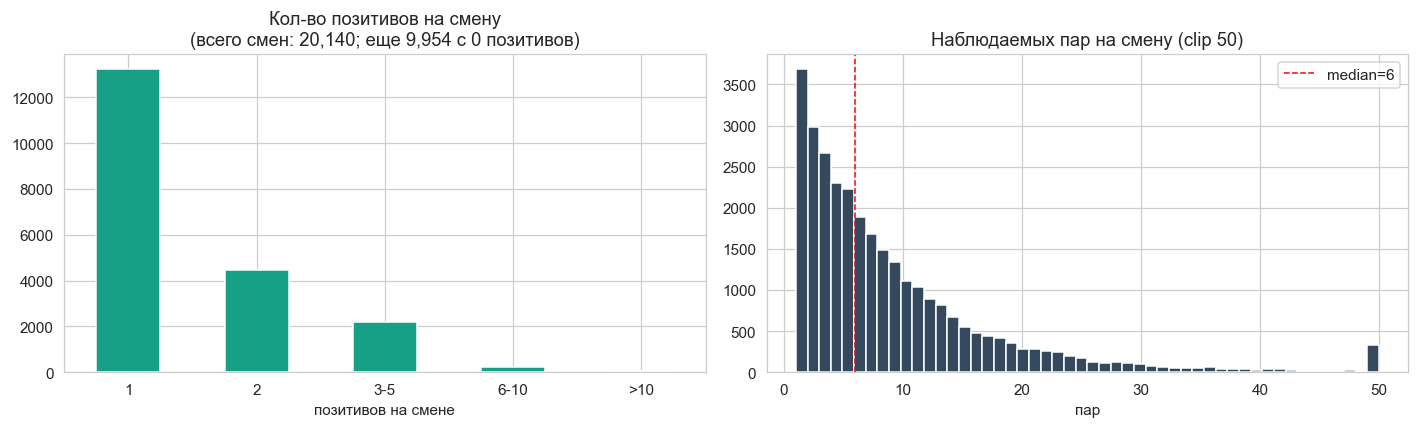

In [26]:
# визуализация
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# распределение позитивов
buckets = pd.cut(pos_per_shift, bins=[0, 1, 2, 5, 10, 50], include_lowest=True,
                 labels=['1', '2', '3-5', '6-10', '>10']).value_counts().sort_index()
buckets.plot.bar(ax=ax[0], color='#16a085')
ax[0].set_title(f'Кол-во позитивов на смену\n(всего смен: {len(pos_per_shift):,}; еще {n_zero:,} с 0 позитивов)')
ax[0].set_xlabel('позитивов на смене')
ax[0].tick_params(axis='x', labelrotation=0)

# наблюдаемых пар на смену
obs_clipped = obs_per_shift.clip(upper=50)
ax[1].hist(obs_clipped, bins=50, color='#34495e', edgecolor='white')
ax[1].set_title(f'Наблюдаемых пар на смену (clip 50)')
ax[1].set_xlabel('пар')
ax[1].axvline(obs_per_shift.median(), color='red', ls='--', lw=1, label=f'median={int(obs_per_shift.median())}')
ax[1].legend()
plt.tight_layout()

### Что мы видим в этих цифрах

**Картина для ranking-loss получается грустная:**

1. **Группы действительно очень маленькие.** Median 6 наблюдаемых пар на смену — это очень мало. Стандартные ranking-функции LambdaRank и YetiRank рассчитаны на группы из десятков-сотен кандидатов с разнообразной разметкой (поисковые системы, рекомендательные системы крупных платформ). У нас этого нет.

2. **33% смен без позитивов вообще.** Для ranking-loss такие смены **бесполезны**: внутри группы нет ни одного «правильного» ответа, и модели не из чего «упорядочивать». LightGBM/CatBoost при `objective='lambdarank'` такие группы либо проигнорирует, либо даст шумный градиент — оба варианта плохие.

3. **44% смен с ровно одним позитивом.** Здесь ranking превращается в **«найди одного правильного из N»**: модели надо построить только пары `(positive, negative)` с одним и тем же позитивом во всех парах. Это работает, но слабый сигнал — каждая такая пара даёт минимум информации.

4. **Только в ~23% смен есть содержательная разметка** для полноценного ranking (2 и более позитивов).

### Что это значит для выбора модели

**Скорректированная рекомендация по loss-функциям** (предыдущая в разделе 6 была слишком категоричной — там я предлагал сразу идти в LambdaRank/YetiRank, но без анализа размера групп):

- **Pointwise binary classification** — реалистичный рабочий вариант. CatBoost/LightGBM с `objective='binary'` (logistic loss). На наших маленьких группах он не уступит ranking-loss, потому что у ranking-loss нет статистики чтобы его обойти.
- **Ranking-loss (LambdaRank, YetiRank)** имеет смысл только **после** реализации negative sampling из раздела 7.5. Negative sampling раздует размер групп до 50-100+ кандидатов на смену, и тогда ranking-loss получит нужную статистику для работы.
- **Listwise (softmax-style) loss** в нашем сетапе сомнителен — большинство групп тривиальные (0-1 позитив), softmax будет в основном тренироваться на вырожденных листах.

### Эмпирическое решение

Это нужно проверить экспериментально на validation, но направление такое:

**baseline → pointwise binary + хороший feature engineering > ranking-loss из коробки**

Если время позволит — попробовать ranking-loss после реализации negative sampling и сравнить.

## 8. Чек-сводка для команды

**Качество данных**
- 383883 события, 5 колонок, без NaN и дубликатов.
- ❗ Контракт нарушен по `ts`: должен был быть ISO-8601 datetime, а пришли только даты (YYYY-MM-DD). На leak-фильтр влияет минимально, но baseline стоит обновить пометкой об этом.
- Ссылочная целостность 100%: ни одного user_id или shift_id в events, которого не было бы в user/shift таблицах.

**Главные количественные находки**
1. **Реальный target rate = 11.5%** (после leak-фильтра, на наблюдаемых парах). Дисбаланс negative/positive ≈ 7.7 к 1.
2. **Воронка APPLY → реальный выход: 37%**. Из тех кто откликнулся, только треть реально доходит до FINISHED (21.5% USER_CANCEL, 26% SYSTEM_CANCEL).
3. **27% юзеров и 25% смен — без событий вообще**. Cold-start — реальная проблема.
4. **Юзеры с `has_mk=True` в 3 раза активнее** (медиана 46 vs 14 событий).
5. **Утечка в leak-фильтре минимальная** (0.18% событий после старта смены, в основном FINISHED). Но есть **вторая утечка в исторических агрегатах baseline** (`user_hist_*` считаются по всему датасету) — см. раздел 7.6. Её нужно чинить через time-aware агрегации.
6. ❗ **Train/serving skew**: в train ~275K пар, в проде модель будет оценивать ~22.8M пар (юзер × смена в той же локации). Train покрывает лишь ~1% prod-распределения — главный концептуальный риск, см. раздел 7.5.
7. **Группы под ranking-loss маленькие** (median 6 пар на смену, 33% смен с 0 позитивов, 44% с ровно 1 позитивом). LambdaRank/YetiRank из коробки на таком сетапе работают плохо. См. раздел 7.7.

**Вопросы команде, которые стоит обсудить**
- Текущий target = `APPLY OR FINISHED` — это «готов попробовать», а не «реально выйдет». **Менять target на `FINISHED` для leaderboard нельзя без подтверждения**: если eval организаторов считается на их target, любая смена просадит метрику. Но `FINISHED` можно использовать как **auxiliary target** (sample_weight в loss или вторая голова в multi-task).
- ~~Имеет смысл сразу идти в ranking-loss.~~ **Скорректировано (см. 7.7):** ranking-loss имеет смысл только **после** реализации negative sampling, иначе группы слишком маленькие. Сейчас рабочий старт — pointwise binary classification с хорошим feature engineering.
- Negative sampling — критично для приближения train к prod. Сэмплировать из юзеров той же локации с применением hard rules (см. `EDA_SUMMARY.md`).
- Time-aware пересчёт исторических признаков — ломает оптимистичный bias на train, см. 7.6.

**Что добавить в feature engineering** (поверх того что уже в baseline; полная приоритизация в `EDA_SUMMARY.md`)
- `is_cold_user` — флаг, что у юзера 0 истории.
- `user_apply_rate` = APPLY / VIEW (time-aware!).
- `user_finished_rate` = FINISHED / APPLY (time-aware!).
- `user_cancel_rate` = (USER_CANCEL + SYSTEM_CANCEL) / APPLY (time-aware!).
- `shift_view_count_so_far` — сколько просмотров уже накопила смена. **⚠ Доступность в serving неоднозначна** — см. таблицу feature availability в `EDA_SUMMARY.md`.
- `task_type_apply_rate` — норма конверсии внутри типа задачи (out-of-fold расчёт обязателен).

**Важно для train/val split (общий вывод по всем трём таблицам)**
Распределение по времени крайне неоднородное:
- январь: ~1000 смен/день в среднем (max 1497)
- с 8 февраля: ~21 смен/день
- target rate в эти периоды разный (12% vs 25%)

Дефолтный `_time_split(test_ratio=0.2)` даёт 96/4 по строкам и сравнивает несравнимые периоды. Стоит:
- либо переписать сплит на percentile по строкам, не по таймстемпам;
- либо использовать первые ~30 дней января как train + последние 30 как test (rolling), но тогда test будет очень разреженным;
- либо договориться с организаторами проверить, что `validation/shift.csv` — это плотный или разрежённый период, и тренироваться на соответствующем.